# ARTI 502 – Deep Learning

## Assignment 2: Training and Testing CNN with CIFAR-10 Dataset Using PyTorch



Task 1: Getting the CIFAR-10 Dataset

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

# Define the dataset path
DATA_PATH = './data'

# Load the CIFAR-10 training dataset
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True
)

# Load the CIFAR-10 testing dataset
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True
)

# Verify dataset loading
print("\nCIFAR-10 Dataset Loaded Successfully!")
print("Number of Training Images:", len(train_dataset))
print("Number of Testing Images:", len(test_dataset))
print("Number of Classes:", len(train_dataset.classes))
print("Classes:", train_dataset.classes)


CIFAR-10 Dataset Loaded Successfully!
Number of Training Images: 50000
Number of Testing Images: 10000
Number of Classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


Task 2: Defining the Network



In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:
# nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0)
#   in_channels  : number of channels in the input (3 for RGB)
#   out_channels : number of filters (= channels in the output)
#   kernel_size  : filter size (3 -> 3x3)
#   stride       : step size of the filter (optional, default 1)
#   padding      : zeros added around the border (optional, default 0)
#                  padding=1 with a 3x3 kernel keeps height/width the same
# nn.MaxPool2d(2, 2) halves the height and width.

class CIFAR10_CNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CIFAR10_CNN, self).__init__()

        # Block 1: 3x32x32 -> 32x16x16
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        # Block 2: 32x16x16 -> 64x8x8
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1)
        self.bn4 = nn.BatchNorm2d(64)

        # Block 3: 64x8x8 -> 128x4x4
        self.conv5 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.bn5 = nn.BatchNorm2d(128)
        self.conv6 = nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1)
        self.bn6 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout(0.5)

        # Classifier: flattened features -> 10 classes
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # Feature extraction (convolution + maxpooling)
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # -> 32x16x16

        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))   # -> 64x8x8

        x = F.relu(self.bn5(self.conv5(x)))
        x = self.pool(F.relu(self.bn6(self.conv6(x))))   # -> 128x4x4

        # Classifier
        x = torch.flatten(x, 1)                          # -> 2048
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)                                  # -> 10 class scores
        return x


model = CIFAR10_CNN().to(device)
print(model)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {num_params:,}")

# Sanity check with a fake batch of 4 RGB 32x32 images
dummy = torch.randn(4, 3, 32, 32).to(device)
print("Input shape :", dummy.shape)
print("Output shape:", model(dummy).shape)   # expected: torch.Size([4, 10])

CIFAR10_CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn6): BatchNorm2d(1

In [4]:
def train(model, device, train_loader, optimizer, criterion, epoch):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()              # 1. clear old gradients
        outputs = model(images)            # 2. forward pass
        loss = criterion(outputs, labels)  # 3. compute loss
        loss.backward()                    # 4. backpropagation
        optimizer.step()                   # 5. update weights

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        if batch_idx % 100 == 0:
            print(f"Epoch {epoch} [{batch_idx * len(images)}/{len(train_loader.dataset)}]"
                  f"  Loss: {loss.item():.4f}")

    avg_loss = running_loss / total
    accuracy = 100.0 * correct / total
    print(f"==> Epoch {epoch} Train Loss: {avg_loss:.4f} | Train Acc: {accuracy:.2f}%")
    return avg_loss, accuracy

In [5]:
def test(model, device, test_loader, criterion):
    model.eval()
    test_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():                  # no gradients during evaluation
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    avg_loss = test_loss / total
    accuracy = 100.0 * correct / total
    print(f"==> Test Loss: {avg_loss:.4f} | Test Acc: {accuracy:.2f}% ({correct}/{total})")
    return avg_loss, accuracy

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Usage once the DataLoaders from Task 3 exist:
# for epoch in range(1, num_epochs + 1):
#     train_loss, train_acc = train(model, device, train_loader, optimizer, criterion, epoch)
#     test_loss, test_acc = test(model, device, test_loader, criterion)

Task 3: Loading Data



In [7]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Convert PIL images to tensors with shape [C, H, W]
transform = transforms.ToTensor()
train_dataset.transform = transform
test_dataset.transform = transform

# Create training and testing DataLoaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Get one batch of training images and labels
images, labels = next(iter(train_loader))

print("Training images tensor size:", images.shape)
print("Training labels tensor size:", labels.shape)

test_images, test_labels = next(iter(test_loader))
print("Testing images tensor size:", test_images.shape)
print("Testing labels tensor size:", test_labels.shape)

Training images tensor size: torch.Size([64, 3, 32, 32])
Training labels tensor size: torch.Size([64])
Testing images tensor size: torch.Size([64, 3, 32, 32])
Testing labels tensor size: torch.Size([64])


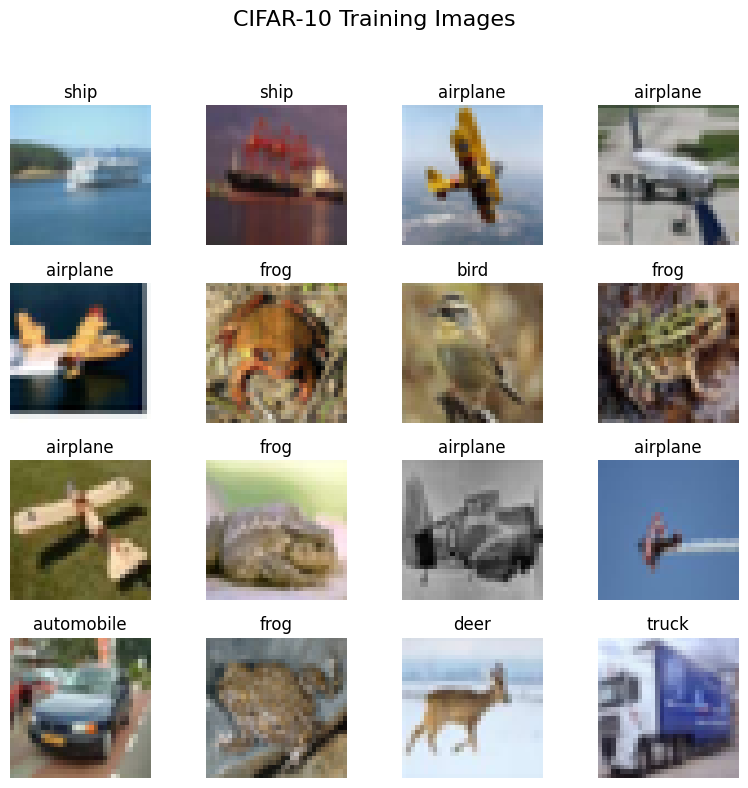

In [8]:
# Display 16 images from the loaded training batch
classes = train_dataset.classes

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    # Matplotlib expects [H, W, C] instead of [C, H, W]
    image = images[i].permute(1, 2, 0).numpy()

    ax.imshow(image)
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

fig.suptitle("CIFAR-10 Training Images", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Task 4: Dataset Augmentation


In [9]:
import numpy as np
import torch
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# CIFAR-10 per-channel mean and std (R, G, B), used by Normalize
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

# ---------- Augmentation 7: various types of noise (custom transforms) ----------
# These work on tensors in the [0, 1] range, so they go AFTER ToTensor
# and BEFORE Normalize.

class AddGaussianNoise:
    """Adds random values from a normal (bell-curve) distribution to every pixel."""
    def __init__(self, mean=0.0, std=0.05):
        self.mean, self.std = mean, std
    def __call__(self, tensor):
        noisy = tensor + torch.randn_like(tensor) * self.std + self.mean
        return noisy.clamp(0.0, 1.0)
    def __repr__(self):
        return f"AddGaussianNoise(mean={self.mean}, std={self.std})"

class AddSaltPepperNoise:
    """Randomly sets some pixels to pure black (pepper) or pure white (salt)."""
    def __init__(self, amount=0.02):
        self.amount = amount
    def __call__(self, tensor):
        noisy = tensor.clone()
        mask = torch.rand(tensor.shape[1:])           # one random value per pixel (H x W)
        noisy[:, mask < self.amount / 2] = 0.0         # pepper
        noisy[:, mask > 1 - self.amount / 2] = 1.0     # salt
        return noisy
    def __repr__(self):
        return f"AddSaltPepperNoise(amount={self.amount})"

class AddSpeckleNoise:
    """Multiplicative noise: brighter pixels get more noise (pixel + pixel * noise)."""
    def __init__(self, std=0.1):
        self.std = std
    def __call__(self, tensor):
        noisy = tensor + tensor * torch.randn_like(tensor) * self.std
        return noisy.clamp(0.0, 1.0)
    def __repr__(self):
        return f"AddSpeckleNoise(std={self.std})"

In [10]:
# ---------------- TRAINING transforms (all augmentations) ----------------
train_transform = transforms.Compose([
    transforms.ToPILImage(),                                   # 1. numpy HxWxC -> PIL image
    transforms.RandomHorizontalFlip(p=0.5),                    # 2. mirror left-right
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0),
                                 ratio=(0.9, 1.1)),            # 3. random crop, resized back to 32x32
    transforms.ColorJitter(brightness=0.2, contrast=0.2,
                           saturation=0.2, hue=0.05),          # 4. random color changes
    transforms.RandomRotation(degrees=15),                     # 5. rotate up to ±15 degrees
    transforms.ToTensor(),                                     # 8. PIL -> tensor CxHxW in [0, 1]
    transforms.RandomApply([                                   # 7. noise (50% of the time,
        transforms.RandomChoice([                              #    one noise type chosen at random)
            AddGaussianNoise(std=0.05),
            AddSaltPepperNoise(amount=0.02),
            AddSpeckleNoise(std=0.1),
        ])
    ], p=0.5),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),               # 6. normalize each channel
])

# ---------------- TEST transforms (NO random augmentation, NO noise) ----------------
# Only convert to tensor and normalize with the SAME mean/std as training,
# so the test images are measured exactly as they are.
test_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

print("Train transform:\n", train_transform)
print("\nTest transform:\n", test_transform)


# Small Dataset wrapper: uses the raw CIFAR numpy arrays (N x 32 x 32 x 3, uint8),
# which is why ToPILImage is needed as the first step.
class AugmentedCIFAR10(Dataset):
    def __init__(self, data, targets, transform=None):
        self.data = data
        self.targets = targets
        self.transform = transform
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        image, label = self.data[idx], self.targets[idx]
        if self.transform:
            image = self.transform(image)
        return image, label

aug_train_dataset = AugmentedCIFAR10(train_dataset.data, train_dataset.targets, train_transform)
aug_test_dataset  = AugmentedCIFAR10(test_dataset.data,  test_dataset.targets,  test_transform)

batch_size = 64
train_loader = DataLoader(aug_train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(aug_test_dataset,  batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True)

images, labels = next(iter(train_loader))
print("\nAugmented training batch size:", images.shape)
print("Pixel range after Normalize: min = %.3f, max = %.3f" % (images.min(), images.max()))

Train transform:
 Compose(
    ToPILImage()
    RandomHorizontalFlip(p=0.5)
    RandomResizedCrop(size=(32, 32), scale=(0.8, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    RandomApply(
    p=0.5
    RandomChoice(
    AddGaussianNoise(mean=0.0, std=0.05)
    AddSaltPepperNoise(amount=0.02)
    AddSpeckleNoise(std=0.1)
)(p=None)
)
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Test transform:
 Compose(
    ToPILImage()
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)

Augmented training batch size: torch.Size([64, 3, 32, 32])
Pixel range after Normalize: min = -1.989, max = 2.126


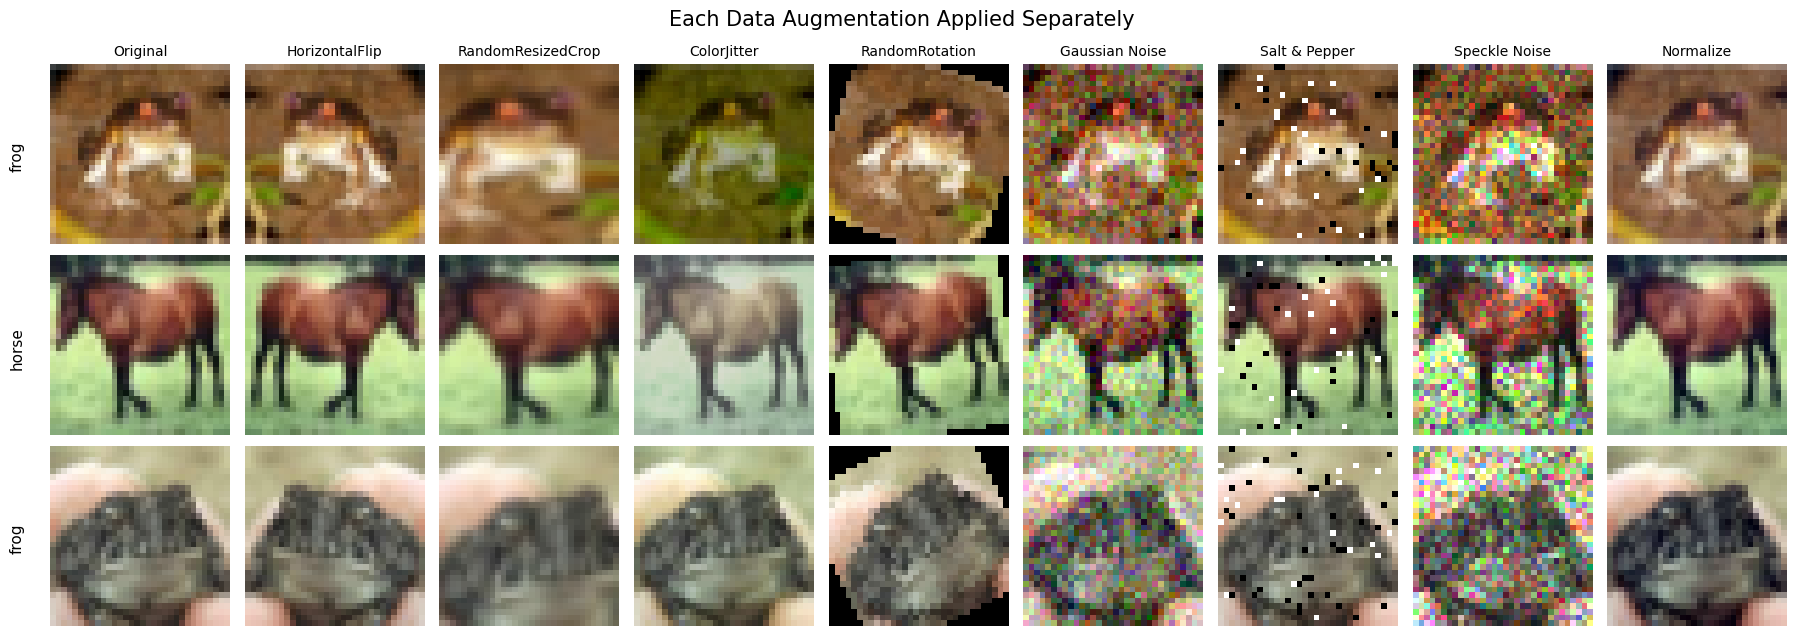

In [11]:
# The strengths here are exaggerated on purpose so each effect is easy to see.
demo_transforms = [
    ("Original",          None),
    ("HorizontalFlip",    transforms.RandomHorizontalFlip(p=1.0)),
    ("RandomResizedCrop", transforms.RandomResizedCrop(32, scale=(0.5, 0.8))),
    ("ColorJitter",       transforms.ColorJitter(0.5, 0.5, 0.5, 0.1)),
    ("RandomRotation",    transforms.RandomRotation(30)),
    ("Gaussian Noise",    AddGaussianNoise(std=0.1)),
    ("Salt & Pepper",     AddSaltPepperNoise(amount=0.05)),
    ("Speckle Noise",     AddSpeckleNoise(std=0.3)),
    ("Normalize",         transforms.Normalize(CIFAR_MEAN, CIFAR_STD)),
]
tensor_only = (AddGaussianNoise, AddSaltPepperNoise, AddSpeckleNoise, transforms.Normalize)

def apply_single(img_np, t):
    if t is None:
        pipeline = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor()])
    elif isinstance(t, tensor_only):   # tensor-based transforms come after ToTensor
        pipeline = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), t])
    else:                              # PIL-based transforms come before ToTensor
        pipeline = transforms.Compose([transforms.ToPILImage(), t, transforms.ToTensor()])
    return pipeline(img_np)

sample_ids = [0, 7, 25]
classes = train_dataset.classes
fig, axes = plt.subplots(len(sample_ids), len(demo_transforms), figsize=(18, 6.5))

for r, idx in enumerate(sample_ids):
    img_np = train_dataset.data[idx]
    for c, (name, t) in enumerate(demo_transforms):
        out = apply_single(img_np, t)
        if name == "Normalize":        # rescale to [0, 1] only so it can be displayed
            out = (out - out.min()) / (out.max() - out.min())
        axes[r, c].imshow(out.permute(1, 2, 0).numpy())
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(name, fontsize=10)
    axes[r, 0].text(-5, 16, classes[train_dataset.targets[idx]],
                    rotation=90, va="center", ha="right", fontsize=11)

fig.suptitle("Each Data Augmentation Applied Separately", fontsize=15)
plt.tight_layout()
plt.show()

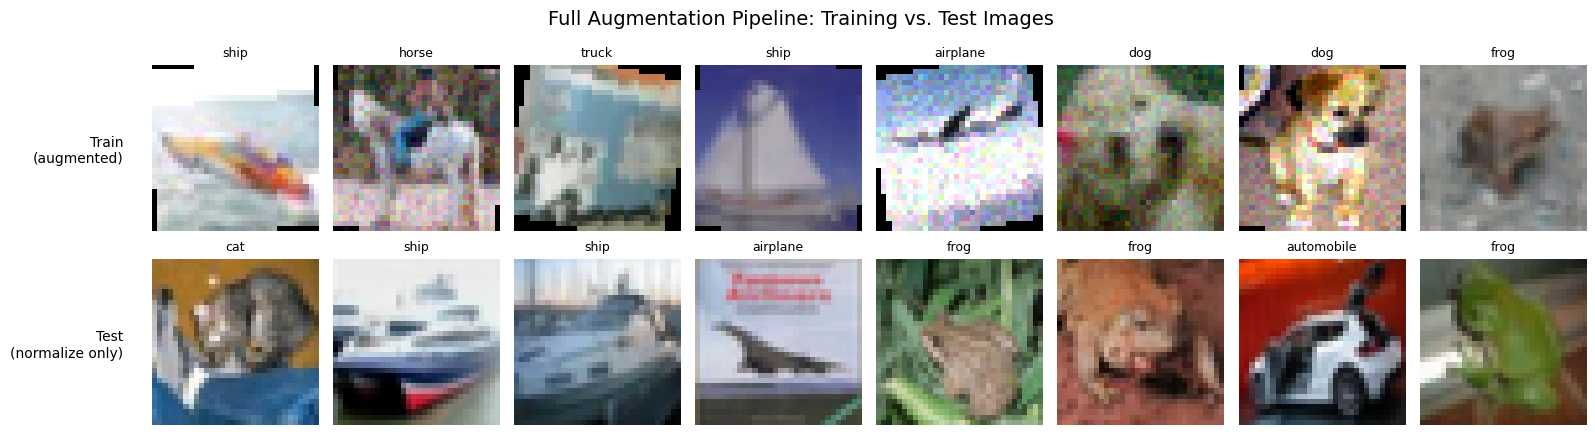

In [12]:
def denormalize(t):
    """Undo Normalize so images look natural when plotted."""
    mean = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
    std  = torch.tensor(CIFAR_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1)

train_imgs, train_lbls = next(iter(train_loader))
test_imgs,  test_lbls  = next(iter(test_loader))

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i in range(8):
    axes[0, i].imshow(denormalize(train_imgs[i]).permute(1, 2, 0).numpy())
    axes[0, i].set_title(classes[train_lbls[i].item()], fontsize=9)
    axes[0, i].axis("off")
    axes[1, i].imshow(denormalize(test_imgs[i]).permute(1, 2, 0).numpy())
    axes[1, i].set_title(classes[test_lbls[i].item()], fontsize=9)
    axes[1, i].axis("off")

axes[0, 0].text(-6, 16, "Train\n(augmented)", ha="right", va="center", fontsize=10)
axes[1, 0].text(-6, 16, "Test\n(normalize only)", ha="right", va="center", fontsize=10)
fig.suptitle("Full Augmentation Pipeline: Training vs. Test Images", fontsize=14)
plt.tight_layout()
plt.show()

Task 5: Training Function and Tuning Hyperparameters


In [13]:
# ---------- Task 5: training function that RECORDS and PLOTS the metrics ----------
import io, contextlib, time
import pandas as pd

def fit(model, train_loader, test_loader, optimizer, num_epochs, scheduler=None, name="model"):
    """Trains with train() and evaluates with test() from Task 2 every epoch,
    and records train loss, train accuracy, test loss and test accuracy."""
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    print(f"\n===== {name} =====")
    for epoch in range(1, num_epochs + 1):
        start = time.time()
        # hide the per-batch prints of train()/test() so the output stays short
        with contextlib.redirect_stdout(io.StringIO()):
            tr_loss, tr_acc = train(model, device, train_loader, optimizer, criterion, epoch)
            te_loss, te_acc = test(model, device, test_loader, criterion)
        if scheduler is not None:
            scheduler.step()

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss)
        history["test_acc"].append(te_acc)
        print(f"Epoch {epoch:2d}/{num_epochs} | train loss {tr_loss:.4f} acc {tr_acc:.2f}% | "
              f"test loss {te_loss:.4f} acc {te_acc:.2f}% | {time.time() - start:.0f}s")
    return history


def plot_history(history, title=""):
    """Plots train loss vs test loss, and train/test accuracy."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train loss")
    axes[0].set_title("Training Loss")
    axes[1].plot(epochs, history["test_loss"], marker="o", color="tab:orange", label="Test loss")
    axes[1].set_title("Test Loss")
    axes[2].plot(epochs, history["test_acc"], marker="o", color="tab:green", label="Test accuracy")
    axes[2].plot(epochs, history["train_acc"], linestyle="--", color="tab:gray", label="Train accuracy")
    axes[2].set_title("Test Accuracy (%)")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel("Cross-entropy loss")
    axes[2].set_ylabel("Accuracy (%)")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

In [14]:
# ---------- A second, smaller architecture to compare against the Task 2 network ----------
# 2 conv layers, no BatchNorm, no Dropout
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)    # 3x32x32  -> 32x32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 32x16x16 -> 64x16x16
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # -> 32x16x16
        x = self.pool(F.relu(self.conv2(x)))   # -> 64x8x8
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# Training set WITHOUT augmentation (only ToTensor + Normalize) to measure the effect of Task 4
noaug_train_dataset = AugmentedCIFAR10(train_dataset.data, train_dataset.targets, test_transform)

def make_loader(dataset, batch_size, shuffle):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=2, pin_memory=True)

test_loader = make_loader(aug_test_dataset, 256, shuffle=False)

In [15]:
# ---------- Hyperparameter / architecture experiments ----------
# Each experiment changes ONE thing compared to the baseline (A).
torch.manual_seed(42)
EXP_EPOCHS = 10

experiments = [
    # name                                    model         optimizer  lr     batch  augmentation
    ("A: CNN, Adam lr=0.001, bs=64, aug",      CIFAR10_CNN,  "adam",    0.001, 64,    True),
    ("B: CNN, Adam lr=0.01, bs=64, aug",       CIFAR10_CNN,  "adam",    0.01,  64,    True),
    ("C: CNN, SGD lr=0.01, bs=64, aug",        CIFAR10_CNN,  "sgd",     0.01,  64,    True),
    ("D: CNN, Adam lr=0.001, bs=128, aug",     CIFAR10_CNN,  "adam",    0.001, 128,   True),
    ("E: CNN, Adam lr=0.001, bs=64, NO aug",   CIFAR10_CNN,  "adam",    0.001, 64,    False),
    ("F: SimpleCNN, Adam lr=0.001, bs=64, aug", SimpleCNN,   "adam",    0.001, 64,    True),
]

def make_optimizer(kind, params, lr):
    if kind == "adam":
        return torch.optim.Adam(params, lr=lr)
    return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)

results, all_histories = [], {}
for name, model_cls, opt_kind, lr, bs, use_aug in experiments:
    exp_model = model_cls().to(device)
    exp_train_loader = make_loader(aug_train_dataset if use_aug else noaug_train_dataset, bs, shuffle=True)
    optimizer = make_optimizer(opt_kind, exp_model.parameters(), lr)

    hist = fit(exp_model, exp_train_loader, test_loader, optimizer, EXP_EPOCHS, name=name)
    all_histories[name] = hist
    results.append({
        "Experiment": name,
        "Final train loss": round(hist["train_loss"][-1], 4),
        "Final test loss": round(hist["test_loss"][-1], 4),
        "Final test acc (%)": round(hist["test_acc"][-1], 2),
        "Best test acc (%)": round(max(hist["test_acc"]), 2),
    })

results_df = pd.DataFrame(results).sort_values("Final test acc (%)", ascending=False)
results_df


===== A: CNN, Adam lr=0.001, bs=64, aug =====
Epoch  1/10 | train loss 1.6505 acc 39.72% | test loss 1.2586 acc 52.91% | 55s
Epoch  2/10 | train loss 1.3406 acc 52.02% | test loss 1.0604 acc 61.48% | 55s
Epoch  3/10 | train loss 1.1949 acc 57.52% | test loss 0.9914 acc 65.31% | 55s
Epoch  4/10 | train loss 1.1092 acc 61.25% | test loss 0.8141 acc 71.43% | 54s
Epoch  5/10 | train loss 1.0336 acc 64.09% | test loss 0.7821 acc 72.62% | 54s
Epoch  6/10 | train loss 0.9829 acc 66.11% | test loss 0.7361 acc 74.95% | 54s
Epoch  7/10 | train loss 0.9390 acc 67.66% | test loss 0.6864 acc 76.37% | 54s
Epoch  8/10 | train loss 0.8894 acc 69.76% | test loss 0.6370 acc 78.19% | 54s
Epoch  9/10 | train loss 0.8536 acc 71.13% | test loss 0.7106 acc 76.76% | 54s
Epoch 10/10 | train loss 0.8285 acc 72.11% | test loss 0.6133 acc 79.33% | 55s

===== B: CNN, Adam lr=0.01, bs=64, aug =====
Epoch  1/10 | train loss 2.2349 acc 16.65% | test loss 1.8725 acc 27.61% | 54s
Epoch  2/10 | train loss 1.9129 acc 25

,Experiment,Final train loss,Final test loss,Final test acc (%),Best test acc (%)
4,"E: CNN, Adam lr=0.001, bs=64, NO aug",0.3278,0.5753,82.30,83.04
2,"C: CNN, SGD lr=0.01, bs=64, aug",0.7478,0.5794,80.35,80.35
3,"D: CNN, Adam lr=0.001, bs=128, aug",0.7792,0.5898,79.65,79.65
0,"A: CNN, Adam lr=0.001, bs=64, aug",0.8285,0.6133,79.33,79.33
5,"F: SimpleCNN, Adam lr=0.001, bs=64, aug",0.8190,0.7982,73.29,73.44
1,"B: CNN, Adam lr=0.01, bs=64, aug",1.2478,0.9433,66.81,66.81


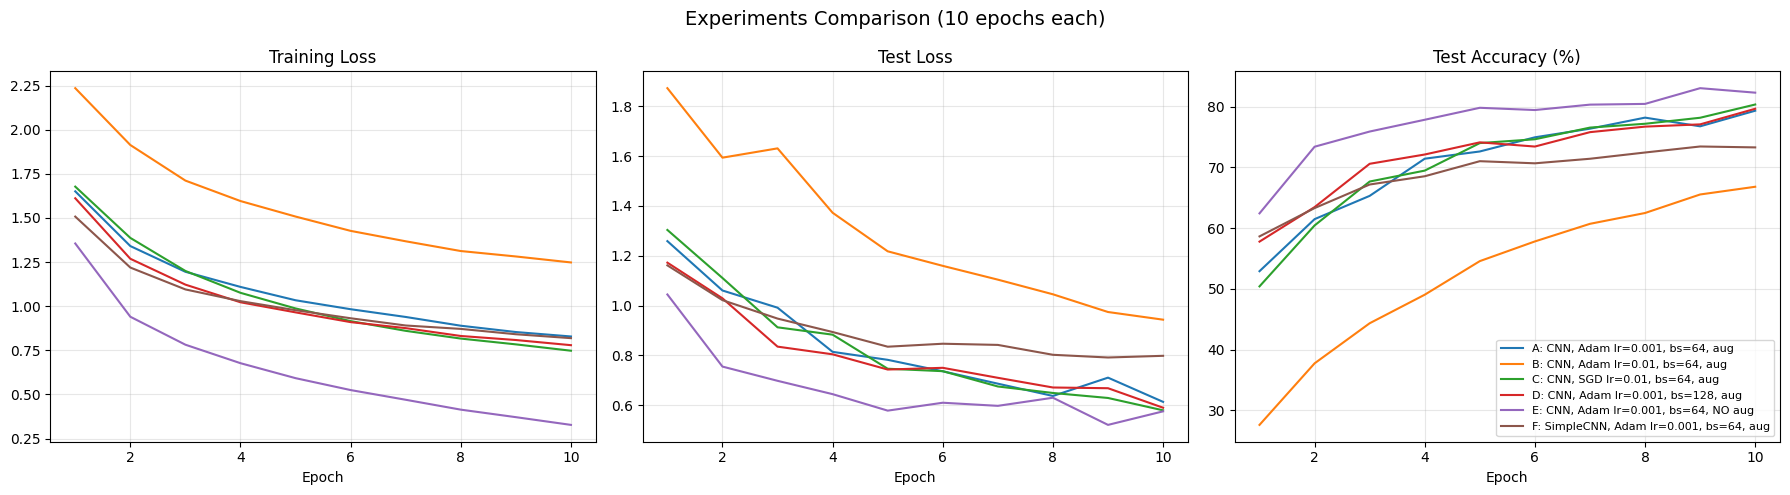

In [16]:
# ---------- Compare all experiments on the same plots ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, hist in all_histories.items():
    ep = range(1, len(hist["test_acc"]) + 1)
    axes[0].plot(ep, hist["train_loss"], label=name)
    axes[1].plot(ep, hist["test_loss"], label=name)
    axes[2].plot(ep, hist["test_acc"], label=name)
for ax, t in zip(axes, ["Training Loss", "Test Loss", "Test Accuracy (%)"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[2].legend(fontsize=8, loc="lower right")
fig.suptitle(f"Experiments Comparison ({EXP_EPOCHS} epochs each)", fontsize=14)
plt.tight_layout()
plt.show()

Best configuration from the experiments: E: CNN, Adam lr=0.001, bs=64, NO aug

===== FINAL: E: CNN, Adam lr=0.001, bs=64, NO aug + CosineAnnealingLR, 30 epochs =====
Epoch  1/30 | train loss 1.3715 acc 49.93% | test loss 1.0091 acc 63.98% | 18s
Epoch  2/30 | train loss 0.9673 acc 65.99% | test loss 0.8437 acc 70.03% | 18s
Epoch  3/30 | train loss 0.8066 acc 72.40% | test loss 0.7354 acc 74.70% | 19s
Epoch  4/30 | train loss 0.7018 acc 76.37% | test loss 0.6181 acc 78.70% | 18s
Epoch  5/30 | train loss 0.6136 acc 79.21% | test loss 0.5906 acc 79.44% | 18s
Epoch  6/30 | train loss 0.5461 acc 81.66% | test loss 0.5660 acc 80.84% | 19s
Epoch  7/30 | train loss 0.4793 acc 83.88% | test loss 0.6321 acc 79.78% | 18s
Epoch  8/30 | train loss 0.4250 acc 85.56% | test loss 0.5195 acc 83.23% | 18s
Epoch  9/30 | train loss 0.3635 acc 87.62% | test loss 0.5512 acc 82.52% | 19s
Epoch 10/30 | train loss 0.3232 acc 88.97% | test loss 0.5572 acc 81.83% | 18s
Epoch 11/30 | train loss 0.2818 acc 90.44% |

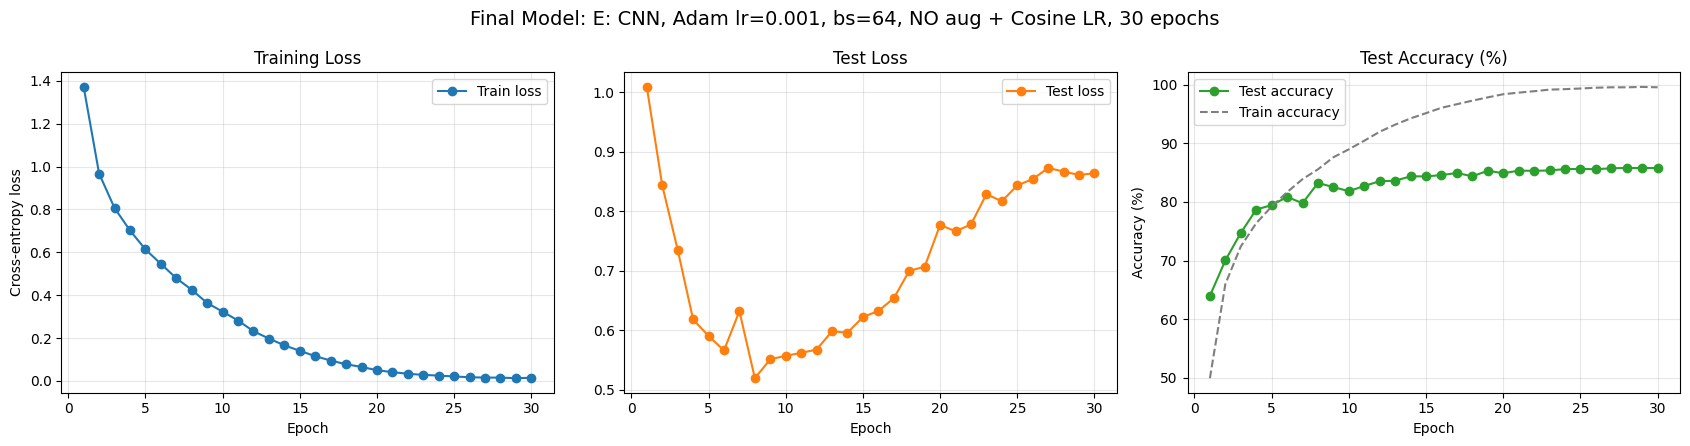


========== FINAL RESULTS ==========
Final train loss    : 0.0147
Final test loss     : 0.8640
Final test accuracy : 85.79%
Best test accuracy  : 85.79% (epoch 28)


In [17]:
# ---------- Final model: best configuration, trained longer ----------
best_name = results_df.iloc[0]["Experiment"]
best_cfg = next(e for e in experiments if e[0] == best_name)
_, model_cls, opt_kind, lr, bs, use_aug = best_cfg
print("Best configuration from the experiments:", best_name)

torch.manual_seed(42)
FINAL_EPOCHS = 30

final_model = model_cls().to(device)
final_train_loader = make_loader(aug_train_dataset if use_aug else noaug_train_dataset, bs, shuffle=True)
final_optimizer = make_optimizer(opt_kind, final_model.parameters(), lr)
# Cosine schedule: learning rate decreases smoothly to ~0 over the epochs
final_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(final_optimizer, T_max=FINAL_EPOCHS)

final_history = fit(final_model, final_train_loader, test_loader, final_optimizer,
                    FINAL_EPOCHS, scheduler=final_scheduler,
                    name=f"FINAL: {best_name} + CosineAnnealingLR, {FINAL_EPOCHS} epochs")

plot_history(final_history, title=f"Final Model: {best_name} + Cosine LR, {FINAL_EPOCHS} epochs")

print("\n========== FINAL RESULTS ==========")
print(f"Final train loss    : {final_history['train_loss'][-1]:.4f}")
print(f"Final test loss     : {final_history['test_loss'][-1]:.4f}")
print(f"Final test accuracy : {final_history['test_acc'][-1]:.2f}%")
print(f"Best test accuracy  : {max(final_history['test_acc']):.2f}% "
      f"(epoch {final_history['test_acc'].index(max(final_history['test_acc'])) + 1})")

### Task 5 – Results Discussion

**Experiments tried** (10 epochs each, changing one thing from baseline A):

| Experiment | What changed | Final train loss | Final test loss | Final test acc |
|---|---|---|---|---|
| A: CNN, Adam lr=0.001, bs=64, aug | Baseline | 0.8285 | 0.6133 | 79.33% |
| B: CNN, Adam lr=0.01, bs=64, aug | Higher learning rate | 1.2478 | 0.9433 | 66.81% |
| C: CNN, SGD lr=0.01, bs=64, aug | SGD (momentum 0.9) instead of Adam | 0.7478 | 0.5794 | 80.35% |
| D: CNN, Adam lr=0.001, bs=128, aug | Larger batch size | 0.7792 | 0.5898 | 79.65% |
| **E: CNN, Adam lr=0.001, bs=64, no aug** | **No data augmentation** | **0.3278** | **0.5753** | **82.30%** |
| F: SimpleCNN, Adam lr=0.001, bs=64, aug | Smaller network (2 conv, no BatchNorm/Dropout) | 0.8190 | 0.7982 | 73.29% |

**Observations:**
- **Learning rate:** lr = 0.01 with Adam was too high. It was the worst run (66.81%) and learned much slower than lr = 0.001.
- **Optimizer:** SGD with momentum (80.35%) was slightly better than Adam (79.33%) with augmentation.
- **Batch size:** 128 vs 64 made almost no difference (79.65% vs 79.33%), but each epoch was a bit faster.
- **Architecture:** the deeper Task 2 CNN (6 conv layers + BatchNorm + Dropout) beat the SimpleCNN by about 6% (79.33% vs 73.29%), so the extra conv layers and BatchNorm helped feature extraction.
- **Data augmentation:** within 10 epochs, training without augmentation gave the best accuracy (82.30%) and each epoch was about 3x faster (≈18s vs ≈54s). The augmented runs had lower train accuracy than test accuracy, because the training images (flips, crops, rotation, color jitter, noise) are harder than the clean test images, so the model needs more epochs to benefit from augmentation.

**What worked best:** the Task 2 CNN (6 conv layers with BatchNorm, MaxPooling, Dropout 0.5) with Adam, lr = 0.001, batch size = 64, without data augmentation (only ToTensor + Normalize).

**Final model:** the best configuration above, trained for 30 epochs with a CosineAnnealingLR schedule (the learning rate decreases smoothly from 0.001 to ~0).

**Final results (epoch 30):**
- Final train loss: **0.0147**
- Final test loss: **0.8640**
- Final test accuracy: **85.79%**

**Plots analysis:** train loss decreased steadily to almost zero (train accuracy 99.55%). The lowest test loss was 0.5195 at epoch 8; after that it increased to 0.8640, while test accuracy kept improving slowly and levelled off at about 85.5–85.8% from epoch 24. The gap between train and test loss shows that the model overfits without augmentation. The model becomes over-confident on the training data, but its test predictions still improved. Training longer with augmentation (or adding weight decay) is the next step to reduce this overfitting.

Task 6: Saving the Source Code

In [18]:
# ---------- Task 6: save the trained model and the results ----------
torch.save(final_model.state_dict(), "cifar10_cnn_final.pth")
results_df.to_csv("experiments_results.csv", index=False)
pd.DataFrame(final_history).to_csv("final_training_history.csv", index_label="epoch")
print("Saved: cifar10_cnn_final.pth, experiments_results.csv, final_training_history.csv")

# Download the files to your computer (Colab only)
try:
    from google.colab import files
    for f in ["cifar10_cnn_final.pth", "experiments_results.csv", "final_training_history.csv"]:
        files.download(f)
except ImportError:
    pass

Saved: cifar10_cnn_final.pth, experiments_results.csv, final_training_history.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>